In [11]:
%load_ext autoreload
%autoreload 2

## Основные библиотеки

In [12]:
import torch
import torchvision

import torch
import torch.nn as nn

from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader, random_split


from torchvision import transforms

from torchvision.transforms import v2

#################################################################
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


from matplotlib.ticker import AutoMinorLocator, MultipleLocator

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder

from sklearn.utils import check_random_state

import os
import json
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pathlib import Path

import pandas as pd
import mlflow
from mlflow import MlflowClient
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection

from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.base import clone

#GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, ParameterSampler
import optuna

from sklearn.preprocessing import StandardScaler #уточнить
from sklearn.base import BaseEstimator,TransformerMixin
#Metrics
from sklearn.metrics import root_mean_squared_error
from sklearn.utils.validation import check_is_fitted
#Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
#Models
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor

from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from catboost import Pool

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import shap
import graphviz

import joblib

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

import mlflow
from mlflow import MlflowClient

import time
import subprocess
import tempfile
from pathlib import Path
from IPython.display import display
import json

import sys
import importlib


In [13]:
import logging
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"

import mlflow

logging.getLogger("mlflow").setLevel(logging.ERROR)

## Импорт локальных библиотек

In [14]:
if 'src.core_funcs' in sys.modules:
    del sys.modules['src.core_funcs']

from src.core_funcs import *

if 'src.modeling.train' in sys.modules:
    del sys.modules['src.modeling.train']
if 'src.utils.drawings' in sys.modules:
    del sys.modules['src.utils.drawings']
if 'src.utils.model_saving' in sys.modules:
    del sys.modules['src.utils.model_saving']
if 'src.feature.features' in sys.modules:
    del sys.modules['src.feature.features']
if 'config' in sys.modules:
    del sys.modules['config'] 
if 'src.custom_models' in sys.modules:
    del sys.modules['src.custom_models'] 
if 'src.mymlflow' in sys.modules:
    del sys.modules['src.mymlflow']
if 'src.feature.feature_selection' in sys.modules:
    del sys.modules['src.feature.feature_selection'] 
if 'src.feature.feature_selection' in sys.modules:
    del sys.modules['src.feature.feature_selection'] 
if 'src.model_saving' in sys.modules:
    del sys.modules['src.model_saving'] 

import src.modeling.train as train
from src.feature.features import FeatureTransformer
from src.feature.features import encoder_transformer
from config import Config
import src.utils.drawings as drawer

from src.custom_models.myMLP import MyModel, Callback, EarlyStopping, CheckpointManager, RMSELoss
from src.feature.feature_selection import count_off_shap
from src.feature.features import DNN_encoder
from src.utils.model_saving import ModelSaver
from src.modeling.predict import Predictor
from src.custom_models.meta_model import MyStackingRidge

In [15]:
if 'config' in sys.modules:
    del sys.modules['config']
from config import Config

In [16]:
if 'config' in sys.modules:
    del sys.modules['config']
from config import Config
if 'src.custom_models' in sys.modules:
    del sys.modules['src.custom_models'] 
from src.custom_models.meta_model import MyStackingRidge
from src.core_funcs import setup_validation
from src.utils.mymlflow import Mlflow_logger
from src.feature.features import FeatureTransformer
from src.custom_models.myMLP import MyModel, Callback, EarlyStopping, CheckpointManager, RMSELoss


## Валидация

In [ ]:
# data = pd.read_csv(Config.path_train_data)

# #Prepare data
# y_train = np.log1p(data['SalePrice'])
# data = data.drop('SalePrice',axis = 1)

# X_train, X_holdout, y_train, y_holdout = train_test_split(
#     data,
#     y_train,
#     test_size=0.2,  # 10% данных уйдет в тест, 90% — в train
#     random_state=Config.seed,  # фиксирует случайность для воспроизводимости
#     shuffle=True,  # перемешивать данные перед разделением (по умолчанию True)
# )

In [17]:
X_train, X_holdout, y_train, y_holdout = setup_validation(Config.path_train_data, test_size = 0.2)

outer_kf = KFold(n_splits=Config.cv, shuffle=True, random_state=Config.seed)
outer_cv_folds = list(outer_kf.split(X_train, y_train))

## Логирование

In [18]:
#cmd - python -m mlflow server --port 5000
logger = Mlflow_logger("House_Prices_Kaggle")
logger.setup_connection()

Start tracking experiments at http://127.0.0.1:5000


## Baseline

### Первый этап, подбор диапазона поиска гиперпараметров вручную

In [28]:
ridge_pipeline = {"ridge": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
            ]),
        "parameters": {
            "model__alpha": np.linspace(0.01,0.1,10),  # np.float64(0.11144234247204798)
            "model__solver": ["svd"],
            "model__max_iter": [2000],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

Outer CV:   0%|          | 0/5 [00:00<?, ?it/s]

Начинаем обучение 10 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (47 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.16054985771045288, best mean val RMSE 0.1547053403101871, best_val_std 0.042924520851791256
Best searched params
model__alpha          0.1
model__max_iter      2000
model__random_state    42
model__solver         svd

Average inner OOF 0.1568720785990459


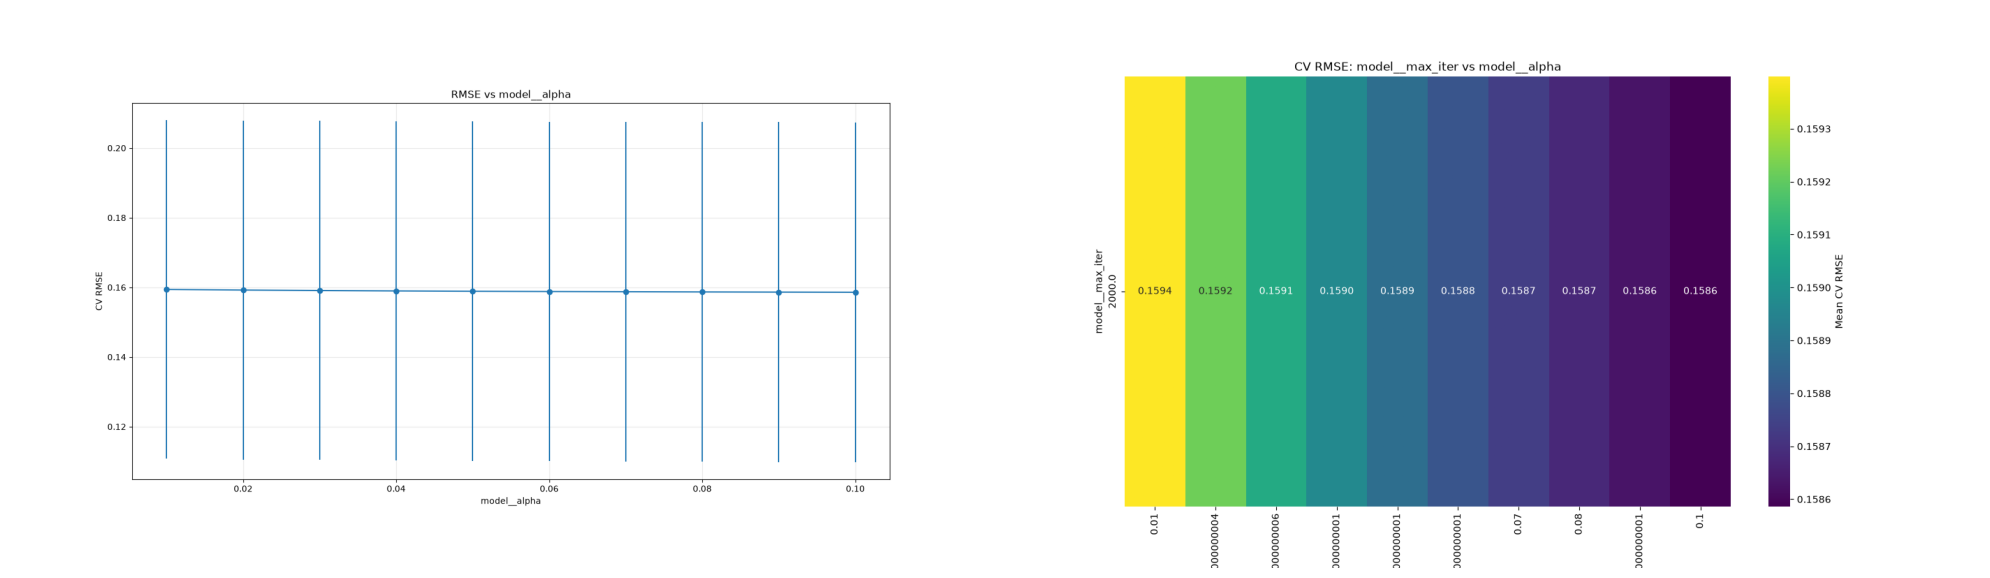

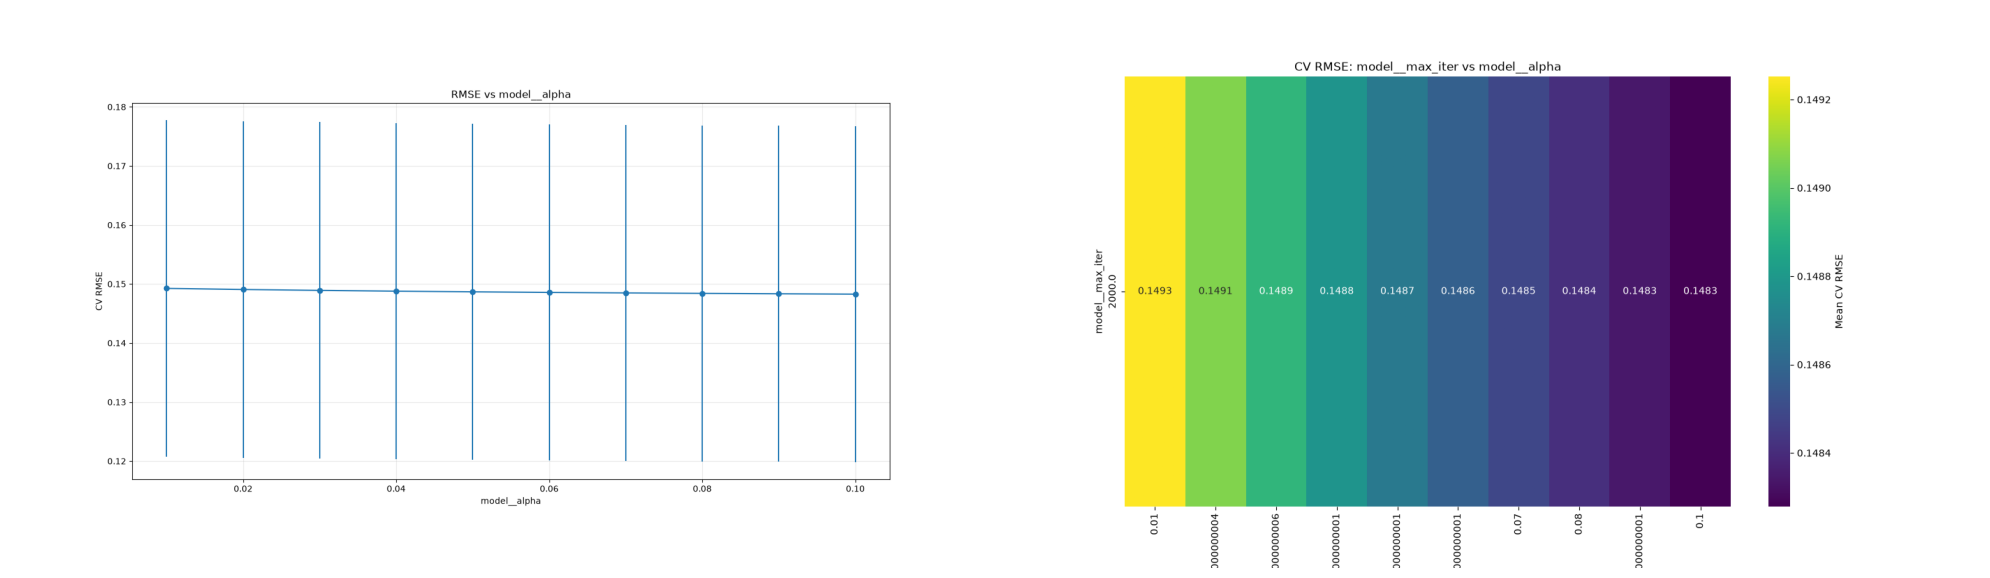

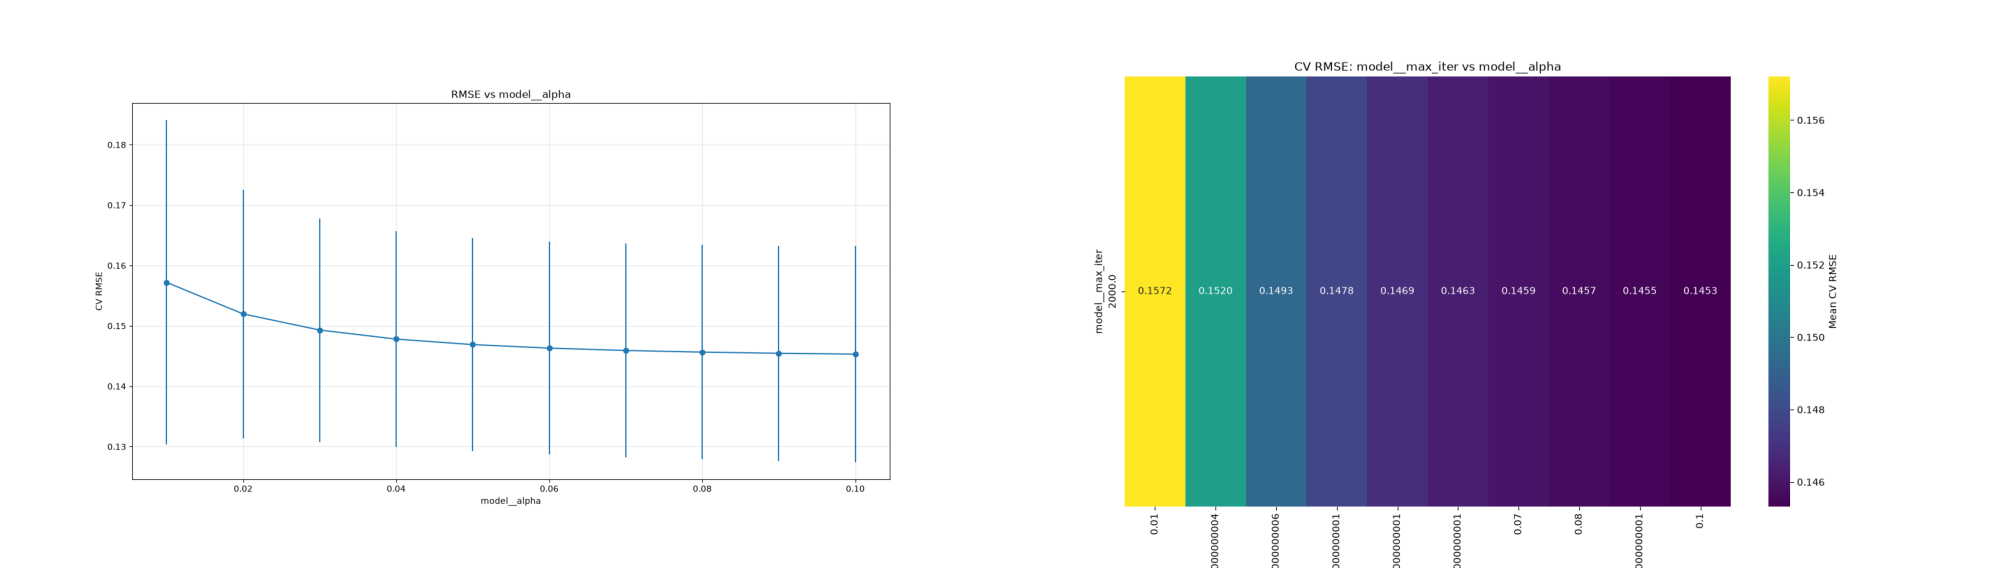

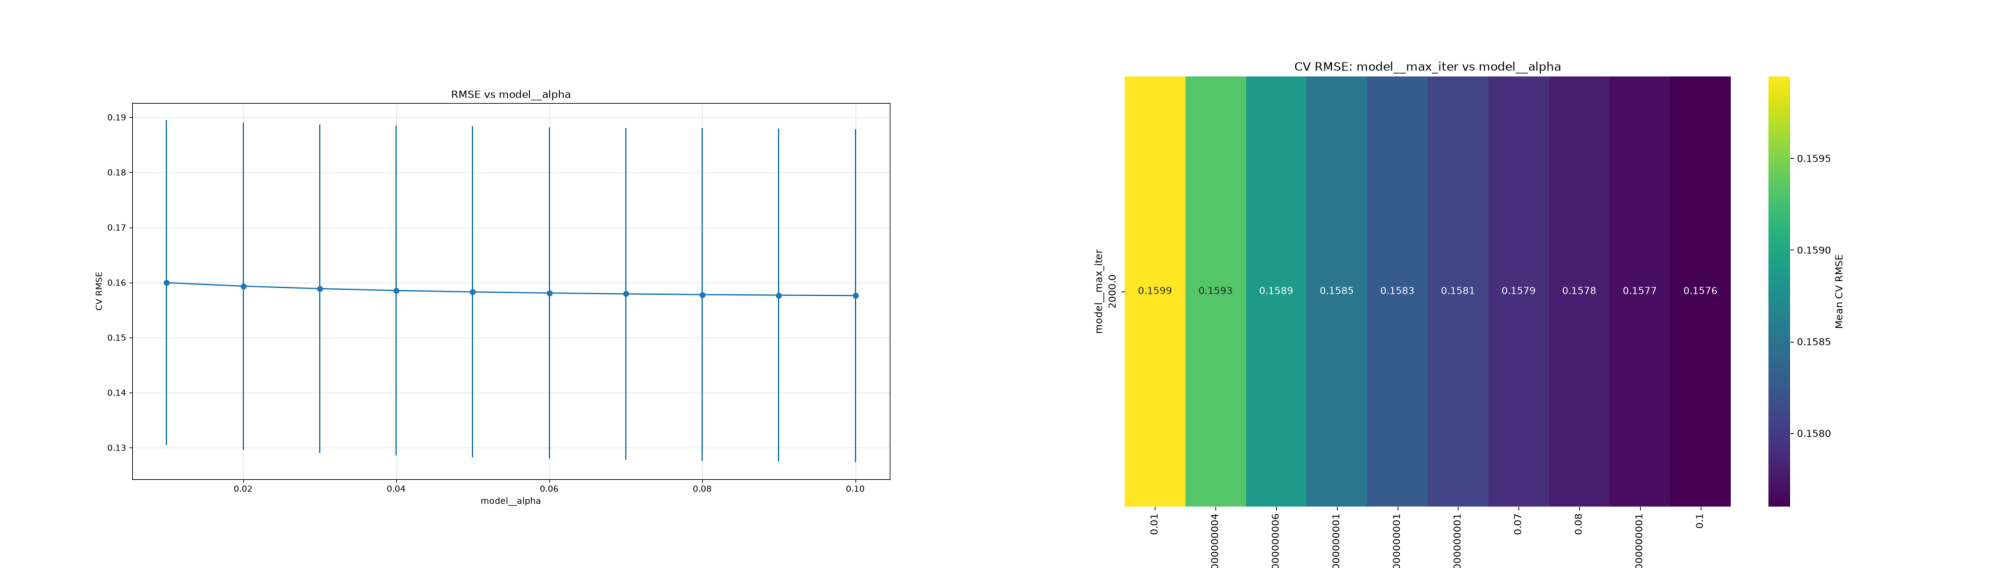

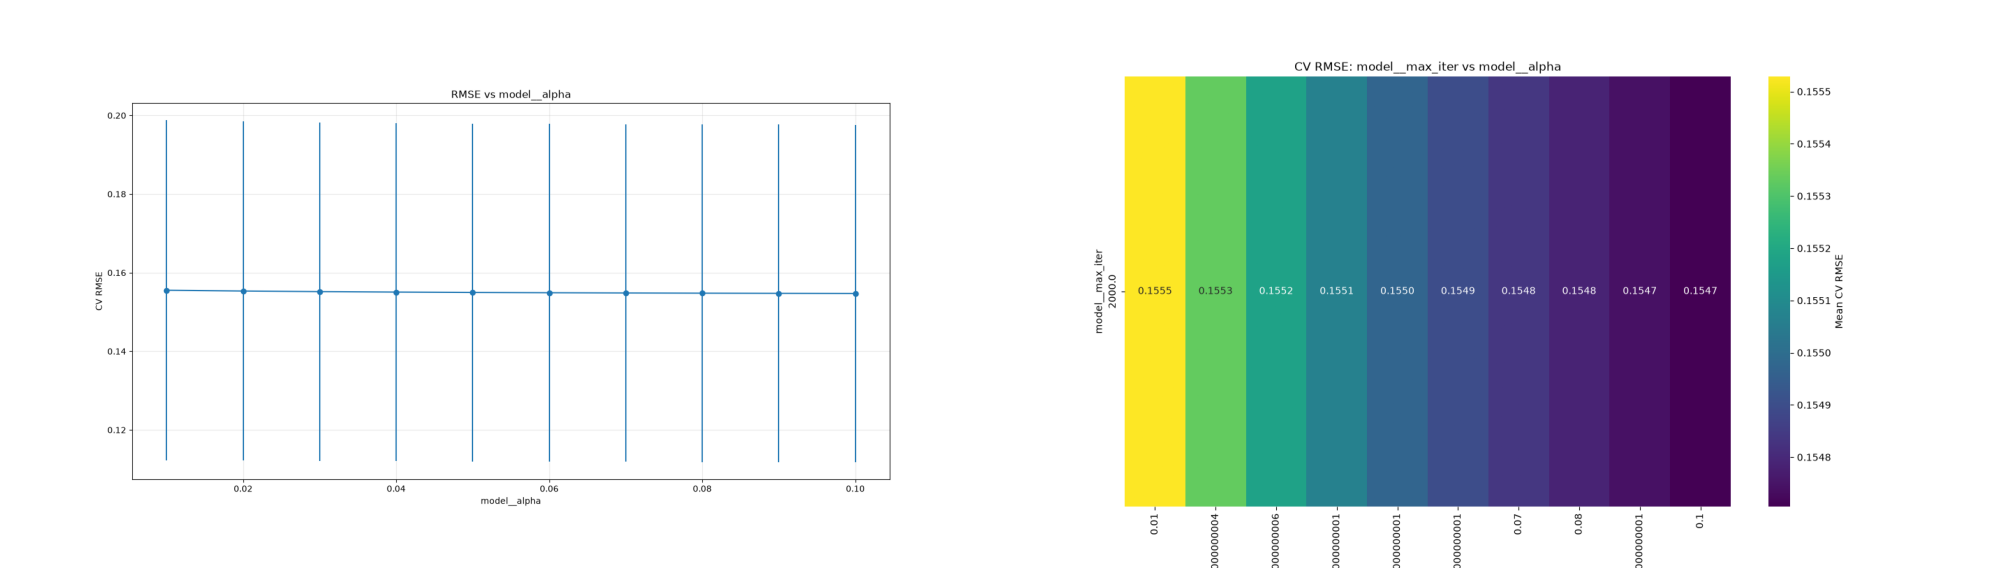

In [29]:
# return {
#     "run_id": run_id,
#     "results_df": results_df,
#     "best_value": oof_rmse,
#     "best_ensemble": pipelines,
#     "for_shap": for_shap,
#     "best_results": best_results,
#     'best_history": best_history,
#     'cv_folds':cv_folds
#     }

all_folds_results = []

for fold_id, (train_idx, val_idx)  in enumerate(tqdm(outer_cv_folds, desc="Outer CV")):
    
    inner_X_train, inner_X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    inner_y_train, inner_y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    
    ridge_results = run_experiment(
        inner_X_train, inner_y_train,
        "ridge",
        ridge_pipeline,
        logger
    )

    all_folds_results.append({
        "fold": fold_id,
        "val_idx": val_idx.copy(),
        "results": ridge_results,
    })

avg_inner_oof_rmse = np.mean([fold['results']['best_value'] for fold in all_folds_results])

print(f"\n\033[31mAverage inner OOF {avg_inner_oof_rmse}\033[0m")

In [ ]:
outer_oof_pred = np.full(len(y_train), np.nan)
coverage = np.zeros(len(y_train), dtype=int)

fold_scores = []

for fold in all_folds_results:
    val_idx = fold['val_idx']
    ensemble = fold['results']['best_ensemble']

    X_outer_val = X_train.iloc[val_idx]
    y_outer_val = y_train.iloc[val_idx]

    pred = np.mean([pipeline.predict(X_outer_val) for pipeline in ensemble],axis=0,).reshape(-1)
    outer_oof_pred[val_idx] = pred

    fold_scores.append(
        root_mean_squared_error(y_outer_val, pred))

    coverage[val_idx] += 1

if not np.all(coverage == 1):
    raise ValueError("Каждая строка должна оцениваться ровно один раз.")

print("Outer OOF RMSE:", root_mean_squared_error(y_train, outer_oof_pred))
print("Mean outer RMSE:", np.mean(fold_scores))
print("Outer RMSE std:", np.std(fold_scores))

### Второй этап, подбор лучших гиперпараметров Optuna

In [ ]:
def suggest_ridge_params(trial):
    return {
        "model__alpha": trial.suggest_float(
            "model__alpha",
            0.001,
            20,
            log=True,
        ),
        "model__max_iter": trial.suggest_int(
            "model__max_iter",
            100,
            1000,
        ),
    }

ridge_optuna_pipeline = {"ridge_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
            ]),
        "parameters_to_search": suggest_ridge_params,
        "search_type": "grid",
        "fit_param": {
            "model__solver": "saga",
            "model__random_state": Config.seed
        },
        "n_iter": 100,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

In [ ]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }

ridge_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "ridge_optuna",
    ridge_optuna_pipeline,
    logger
)

### Третий этап, подсчет SHAP признаков и отбор признаков

In [ ]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

ridge_shap = run_shap(
    X_train,
    ridge_results,
    mode="linear",
    logger = logger
)

In [ ]:
# return {
#     "results_df": results_df,
#     "best_ensemble": best_ensemble,
#     "best_oof_score": best_oof_score,
#     "best_results": fs_best_results,
#     "best_history": best_history,
#     "figures": fig
# }

ridge_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=ridge_results['cv_folds'],
    importance=ridge_shap['importance'],
    search_results=ridge_results['best_results'],
    model_name="ridge",
    model_configs=ridge_pipeline,
    model_run_id=ridge_results['run_id'],
    logger=logger
)

if ridge_fs_results["best_oof_score"] < ridge_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(ridge_fs_results['best_ensemble'],"ridge", save_fs=ridge_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(ridge_results['best_ensemble'],"ridge")

## Lasso

In [ ]:
lasso_pipeline = {"lasso": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Lasso()),
            ]),
        "parameters": {
            "model__alpha": [0.0036868686868686868],  # np.float64(0.11144234247204798)
            "model__max_iter": [100],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

In [ ]:
lasso_results = run_experiment(
    X_train, y_train,
    "lasso",
    lasso_pipeline,
    logger
)

ModelSaver.save_ensemble(lasso_results['best_ensemble'],"lasso")

In [ ]:
lasso_shap = run_shap(
    X_train,
    lasso_results,
    mode="linear",
    logger = logger
)

## DNN

In [ ]:
dnn_pipeline = {"dnn": {
                "pipeline": Pipeline([
                    ("feature_transform", FeatureTransformer()),
                    ("encoder", DNN_encoder()),
                    ("model", MyModel()),
                ]),

                "parameters": {
                    # Данные
                    "model__cat_cols": [FeatureTransformer.cat_cols],
                    "model__num_cols": [FeatureTransformer.num_cols],
                    # Обучение
                    "model__epochs": [1000],
                    "model__device": [Config.device],
                    # Архитектура
                    "model__emb_dim": [12],
                    "model__inner_n": [512],
                    "model__drop_n": [0.1],
                    "model__n_layers": [1],
                    "model__use_batchnorm": [True],
                    # Loss
                    "model__loss_reg": [RMSELoss],
                    #Regularization
                    "model__l1_lambda":[0.003433628682365358],
                    # Optimizer
                    "model__optim": [torch.optim.Adam],
                    "model__optim_lr": [0.08686979995821902],
                    # Scheduler
                    "model__scheduler": [
                        torch.optim.lr_scheduler.ReduceLROnPlateau
                    ],
                    "model__lr_scheduler": [True],
                    "model__factor": [0.08066252499544253],
                    "model__patience": [15],
                    "model__threshold": [0.01],
                    "model__min_lr": [1e-10],
                    # Early Stopping
                    "model__early_stopping_patience": [45],
                    "model__early_stopping_threshold": [0.001],
                    # DataLoader
                    "model__batch_size": [64],
                    # Checkpoint
                    "model__saving_threshold": [0.001],
                    "model__save_path": ["checkpoints"],
                },
                "search_type": "grid",
                "fit_param": {"model__callbacks":[CheckpointManager(),EarlyStopping()]}, #,MLflow_logger()
                "n_iter": 1, #для рандом серча
                "plot_param": "model__optim_lr",
                "heatmap_params": ("model__optim_lr", "model__n_layers"),
                "shap_mode": "dnn",
                "cv": 5,
                "n_jobs": 1,
        }
}

In [ ]:
# return {
#     "run_id": run_id,
#     "results_df": results_df,
#     "oof_rmse": oof_rmse,
#     "best_results": best_results,
#     "for_shap": for_shap,
#     "best_history": best_history,
#     "figures": figures
# }

dnn_results = run_experiment(
    X_train, y_train,
    "dnn",
    dnn_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_dnn_params(trial):
    return {
        "model__emb_dim": trial.suggest_categorical(
            "model__emb_dim",
            [12,24]
        ),
        "model__drop_n": trial.suggest_categorical(
            "model__drop_n",
            [0.1,0.2]
        ),
        "model__n_layers": trial.suggest_categorical(
            "model__n_layers",
            [1,2,3,4]
        ),
        'model__inner_n': trial.suggest_categorical(
            "model__inner_n",
            [64,128,256,512]
        ),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm",
            [True,False]
        ),
        "model__l1_lambda": trial.suggest_float(
            "model__l1_lambda",
            0.001,
            20,
            log=True,
        ),
        "model__optim_lr": trial.suggest_float(
            "model__optim_lr",
            0.00001,
            0.1
        ),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm", 
            [True, False]),
            # Scheduler
        "model__factor": trial.suggest_float(
            "model__factor", 
            0.01,
            0.1
        ),
        "model__patience": trial.suggest_categorical(
            "model__patience", [5,10,15,20]
        ),
        "model__threshold": trial.suggest_categorical(
            "model__threshold", [0.001,0.01,0.1]
        ),
        "model__min_lr": trial.suggest_categorical(
            "model__min_lr", [1e-10]
        ),
        # Early Stopping
        "model__early_stopping_patience": trial.suggest_categorical(
            "model__early_stopping_patience", [20,30,35,45]
        ),
        "model__early_stopping_threshold": trial.suggest_categorical(
            "model__early_stopping_threshold", [0.01, 0.001,0.0001]
        ),
        # DataLoader
        "model__batch_size": trial.suggest_categorical(
            "model__batch_size", [64,128,256,512]
        ),
        # Checkpoint
        "model__saving_threshold": trial.suggest_categorical(
            "model__saving_threshold", [0.001]
        ),
    }

dnn_optuna_pipeline = {"dnn_optuna": {
                "pipeline": Pipeline([
                    ("feature_transform", FeatureTransformer()),
                    ("encoder", DNN_encoder()),
                    ("model", MyModel()),
                ]),

            "parameters_to_search": suggest_dnn_params,
            "search_type": "grid",
            "fit_param": {
                "model__solver": "saga",
                "model__random_state": Config.seed
            },
            "search_type": "grid",
            "fit_param": {"model__callbacks":[CheckpointManager(),EarlyStopping()],
                          "model__device": Config.device,
                          "model__cat_cols": FeatureTransformer.cat_cols,
                          "model__num_cols": FeatureTransformer.num_cols,
                          "model__loss_reg": RMSELoss, #Сделать RMSE losss
                          "model__epochs": 1000,
                          "model__optim": torch.optim.Adam,
                          "model__scheduler":torch.optim.lr_scheduler.ReduceLROnPlateau,
                          "model__lr_scheduler": True,
                          
                          },
            "n_iter": 1, #для оптуны
            "plot_param": "model__optim_lr",
            "heatmap_params": ("model__inner_n", "model__n_layers"),
            "shap_mode": "dnn",
            "cv": 5,
            "n_jobs": -1,
            }}

In [ ]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }
#Добавить функцию сохраненния обученного пайплайна

dnn_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "dnn_optuna",
    dnn_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

dnn_optuna_shap = run_shap(
    X_train,
    dnn_results,
    mode="dnn",
    logger = logger
)

In [ ]:
dnn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=dnn_results['cv_folds'],
    importance=dnn_optuna_shap['importance'],
    search_results=dnn_results['best_results'],
    model_name="dnn",
    model_configs=dnn_pipeline,
    model_run_id=dnn_results['run_id'],
    logger=logger
)

if dnn_fs_results["best_oof_score"] < dnn_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(dnn_fs_results['best_ensemble'],"DNN", save_fs=dnn_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(dnn_results['best_ensemble'],"DNN")

## Catboost

In [ ]:
catboost_pipeline = {"catboost": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
        "parameters": {
            "model__boosting_type": ["Plain"],  # ["Plain", "Ordered"]
            "model__iterations": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.05211448378065621],  # [0.08]
            "model__depth": [4],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bernoulli"],
            "model__thread_count": [-1],
            "model__l2_leaf_reg": [0.01727277227745447],  # np.float64(0.0098)
            "model__rsm": [1.0],  # [0.6, 0.8, 1.0]
            "model__subsample": [0.8],
            "model__border_count": [256],
            "model__min_data_in_leaf": [50],
            "model__max_ctr_complexity": [2],
            "model__one_hot_max_size": [6],
            "model__eval_metric": ["RMSE"],
            "model__loss_function": ["RMSE"],
            "model__random_strength": [1.7444045228543141],  # [0, 0.5, 1, 2]
            "model__verbose": [False],
            "model__random_seed": [Config.seed],
            'model__early_stopping_rounds':[50]
        },
        'fit_param': {"model__cat_features": FeatureTransformer.cat_cols},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": - 1,
    }
}

In [ ]:
catboost_results = run_experiment(
    X_train, y_train,
    "catboost",
    catboost_pipeline,
    logger
)
ModelSaver.save_ensemble(catboost_results['best_ensemble'],"catboost")

### Optuna

In [ ]:
def suggest_catboost_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["Plain"]
        ),
        "model__iterations": trial.suggest_categorical(
            "model__iterations", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__depth": trial.suggest_categorical(
            "model__depth", [4, 5, 6, 8]
        ),
        "model__l2_leaf_reg":trial.suggest_float(
            "model__l2_leaf_reg",
            0.001,
            0.10,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.6,0.8,0.1]
        ),
        "model__border_count": trial.suggest_categorical(
            "model__border_count", [32,64,128,256]
        ),
        "model__min_data_in_leaf": trial.suggest_categorical(
            "model__min_data_in_leaf", [30,35,45,50]
        ),
        "model__max_ctr_complexity": trial.suggest_categorical(
            "model__max_ctr_complexity", [1,2,3,4]
        ),
        "model__one_hot_max_size": trial.suggest_categorical(
            "model__one_hot_max_size", [4,5,6]
        ),
        "model__random_strength": trial.suggest_float(
            'model__random_strength', 
            1e-3, 
            10.0, 
            log=True
        ),
        'model__early_stopping_rounds':trial.suggest_categorical(
            "model__early_stopping_rounds", [25,35,50]
        )
    }

catboost_optuna_pipeline = {
    "catboost_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
            "parameters_to_search": suggest_catboost_params,
            "search_type": "grid",
            "fit_param": {"model__random_seed": Config.seed,
                          "model__cat_features": FeatureTransformer.cat_cols,
                          "model__thread_count": -1,
                          "model__rsm": 1.0,
                          "model__bootstrap_type": "Bernoulli",
                          "model__eval_metric": "RMSE",
                          "model__loss_function": "RMSE",
                          "model__verbose": False,
                          },
            "n_iter": 500, #для оптуны
            "plot_param": "model__learning_rate",
            "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
            "shap_mode": "catboost",
            "cv": 5,
            "n_jobs": 1,
            }
        }

In [ ]:
catboost_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "catboost_optuna",
    catboost_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
catboost_shap = run_shap(
    X_train,
    catboost_results,
    mode="catboost",
    logger = logger
)

In [ ]:
catboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=catboost_results['cv_folds'],
    importance=catboost_shap['importance'],
    search_results=catboost_results['best_results'],
    model_name="catboost",
    model_configs=catboost_pipeline,
    model_run_id=catboost_results['run_id'],
    logger=logger
)

if catboost_fs_results["best_oof_score"] < catboost_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(catboost_fs_results['best_ensemble'],"catboost", save_fs=catboost_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(catboost_results['best_ensemble'],"catboost")

## LightGBM

In [ ]:
lightgbm_pipeline = {"lightgbm": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMRegressor()),
        ]),
        "parameters": {
            "model__device": ["cpu"],
            "model__boosting_type": ["gbdt"],
            "model__n_estimators": [2000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.098],  # np.linspace(0.01, 0.1, 5); [np.float64(0.0775)]
            "model__max_depth": [4],  # [4, 5, 6, 8]
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0]
            "model__reg_alpha": [0.008],  # [0.1, 0.2, 0.4, 0.5, 1]
            "model__reg_lambda": [0.04000000000000001],  # [0.01, 0.1, 0.5, 5, 10]
            "model__objective": ["regression"],
            "model__metric": ["rmse"],
            "model__min_child_samples": [40],
            "model__min_child_weight": [1],  # np.linspace(1, 5, 3, dtype=int)
            "model__min_split_gain": [0.0005],  # np.linspace(0.01, 0.1, 5)
            "model__n_jobs": [-1],
            "model__random_state": [Config.seed],
            "model__verbosity": [-1],
            "model__early_stopping_round":[30]
        },
        "fit_param" : {},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        'shap_mode':'lightgbm',
        "cv": 5,
        "n_jobs": 1,
    }
}

In [ ]:
lightgbm_results = run_experiment(
    X_train, y_train,
    "lightgbm",
    lightgbm_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_lightgbm_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["gbdt",'dart']
        ),
        "model__n_estimators": trial.suggest_categorical(
            "model__n_estimators", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4,5,6,7,8]
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4,0.5,0.6,0.8,1]
        ),
        "model__colsample_bytree": trial.suggest_categorical(
            "model__colsample_bytree", [0.4,0.5,0.6,0.8,1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__min_child_samples": trial.suggest_categorical(
            "model__min_child_samples", [35,40,45,50,55]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            1,
            log=True,
        ),
        "model__min_split_gain": trial.suggest_float(
            "model__min_split_gain",
            0.0001,
            0.01,
            log=True,
        ),
        "model__early_stopping_round":trial.suggest_categorical(
            "model__early_stopping_round", [25,30,35,40,45,50]
        )
    }

lightgbm_optuna_pipeline = {
    "lightgbm_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMRegressor(allow_writing_files=False)),
        ]),
            "parameters_to_search": suggest_lightgbm_params,
            "search_type": "grid",
            "fit_param": {"model__random_seed": Config.seed,
                          "model__cat_features": FeatureTransformer.cat_cols,
                          "model__verbosity": -1,
                          "model__n_jobs" : -1,
                          'model__device' : 'gpu',
                          "model__objective": "regression",
                          "model__metric" : "rmse"
                          },
            "n_iter": 500, #для оптуны
            "plot_param": "model__learning_rate",
            "heatmap_params": ("model__learning_rate", "model__max_depth"),
            "shap_mode": "lightgbm",
            "cv": 5,
            "n_jobs": -1,
            }
        }

In [ ]:
lightgbm_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "lightgbm_optuna",
    lightgbm_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
lightgbm_shap = run_shap(
    X_train,
    lightgbm_results,
    mode="lightgbm",
    logger = logger
)

In [ ]:
lightgbm_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=lightgbm_results['cv_folds'],
    importance=lightgbm_shap['importance'],
    search_results=lightgbm_results['best_results'],
    model_name="lightgbm",
    model_configs=lightgbm_pipeline,
    model_run_id=lightgbm_results['run_id'],
    logger=logger
)

if lightgbm_fs_results["best_oof_score"] < lightgbm_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(lightgbm_fs_results['best_ensemble'],"lightgbm", save_fs=lightgbm_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(lightgbm_results['best_ensemble'],"lightgbm")

## KNN

In [ ]:
knn_pipeline = {"knn": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor()),
        ]),
    "parameters": {
            "model__n_neighbors": np.linspace(4, 30, 15, dtype=int),
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
            "model__n_jobs": [-1],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__n_neighbors",
    "heatmap_params": ("model__n_neighbors", "model__p"),
    "shap_mode": "dnn",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
knn_results = run_experiment(
    X_train, y_train,
    "knn",
    knn_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_knn_params(trial):
    return {
        "model__n_neighbors": trial.suggest_categorical(
            "model__n_neighbors", list(map(int, np.linspace(4, 30, 15, dtype=int)))
        ),
        "model__weights": trial.suggest_categorical(
            "model__weights", ["uniform", "distance"]
        ),
        "model__p": trial.suggest_categorical(
            "model__p", [1, 2]
        ),
    }

knn_optuna_pipeline = {"knn_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor()),
        ]),
    "parameters_to_search": suggest_knn_params,
    "search_type": "grid",
    "fit_param": {"model__n_jobs": -1},
    "n_iter": 1,
    "plot_param": "model__n_neighbors",
    "heatmap_params": ("model__n_neighbors", "model__p"),
    "shap_mode": "knn",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
knn_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "knn_optuna",
    knn_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
knn_optuna_shap = run_shap(
    X_train,
    knn_optuna_results,
    mode="dnn",
    logger=logger
)

In [ ]:
knn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=knn_optuna_results['cv_folds'],
    importance=knn_optuna_shap['importance'],
    search_results=knn_optuna_results['best_results'],
    model_name="knn_optuna",
    model_configs=knn_optuna_pipeline,
    model_run_id=knn_optuna_results['run_id'],
    logger=logger
)
if knn_fs_results["best_oof_score"] < knn_optuna_results['best_results']['best_oof_score']:
    save_ensemble(knn_fs_results['best_ensemble'],"knn", save_fs=knn_fs_results['best_results']['best_cols'])
else:
    save_ensemble(knn_optuna_results['best_ensemble'],"knn")

## Decision Tree

In [ ]:
decision_tree_pipeline = {"decision_tree": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeRegressor()),
        ]),
    "parameters": {
            "model__max_depth": [6],
            "model__criterion": ["squared_error"],
            "model__splitter": ["best"],
            "model__min_samples_split": [36],
            "model__min_samples_leaf": [11],
            "model__max_leaf_nodes": [50],
            "model__min_impurity_decrease": [0],
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
decision_tree_results = run_experiment(
    X_train, y_train,
    "decision_tree",
    decision_tree_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_decision_tree_params(trial):
    return {
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [6]
        ),
        "model__criterion": trial.suggest_categorical(
            "model__criterion", ["squared_error"]
        ),
        "model__splitter": trial.suggest_categorical(
            "model__splitter", ["best"]
        ),
        "model__min_samples_split": trial.suggest_categorical(
            "model__min_samples_split", [36]
        ),
        "model__min_samples_leaf": trial.suggest_categorical(
            "model__min_samples_leaf", [11]
        ),
        "model__max_leaf_nodes": trial.suggest_categorical(
            "model__max_leaf_nodes", [50]
        ),
        "model__min_impurity_decrease": trial.suggest_categorical(
            "model__min_impurity_decrease", [0]
        ),
    }

decision_tree_optuna_pipeline = {"decision_tree_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeRegressor()),
        ]),
    "parameters_to_search": suggest_decision_tree_params,
    "search_type": "grid",
    "fit_param": {"model__random_state": Config.seed},
    "n_iter": 1,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
decision_tree_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "decision_tree_optuna",
    decision_tree_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
decision_tree_optuna_shap = run_shap(
    X_train,
    decision_tree_results,
    mode="tree",
    logger=logger
)

In [ ]:
decision_tree_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=decision_tree_optuna_results['cv_folds'],
    importance=decision_tree_optuna_shap['importance'],
    search_results=decision_tree_optuna_results['best_results'],
    model_name="decision_tree_optuna",
    model_configs=decision_tree_optuna_pipeline,
    model_run_id=decision_tree_optuna_results['run_id'],
    logger=logger
)
if decision_tree_fs_results["best_oof_score"] < decision_tree_optuna_results['best_results']['best_oof_score']:
    save_ensemble(decision_tree_fs_results['best_ensemble'],"decision_tree", save_fs=decision_tree_fs_results['best_results']['best_cols'])
else:
    save_ensemble(decision_tree_optuna_results['best_ensemble'],"decision_tree")

## Random Forest

In [ ]:
random_forest_pipeline = {"random_forest": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor()),
        ]),
    "parameters": {
            # bootstrap=True
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__max_depth": [14],  # 13
            "model__criterion": ["squared_error"],
            "model__n_jobs": [-1],
            "model__min_samples_split": [10],  # np.linspace(10, 100, 5, dtype=int)
            "model__min_samples_leaf": [5],  # np.linspace(5, 15, 5, dtype=int); min_samples_leaf: np.int64(6)
            "model__max_leaf_nodes": [100],  # 75
            "model__min_impurity_decrease": [0],
            "model__max_features": [None],  # "sqrt", "log2"
            "model__bootstrap": [True],
            "model__max_samples": [0.8],
            "model__oob_score": [True],
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_leaf_nodes",
    "heatmap_params": ("model__max_leaf_nodes", "model__max_depth"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
random_forest_results = run_experiment(
    X_train, y_train,
    "random_forest",
    random_forest_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_random_forest_params(trial):
    return {
        "model__n_estimators": trial.suggest_int(
            "model__n_estimators", 100,2000, step=100
        ),
        "model__max_depth": trial.suggest_int(
            "model__max_depth", 10,20, step=1
        ),
        "model__min_samples_split": trial.suggest_int(
            "model__min_samples_split", 5,50, step=5
        ),
        "model__min_samples_leaf": trial.suggest_int(
            "model__min_samples_leaf", 5,50, step=5
        ),
        "model__max_leaf_nodes": trial.suggest_int(
            "model__max_leaf_nodes", 50,100, step=5
        ),
        "model__min_impurity_decrease": trial.suggest_float(
            "model__min_impurity_decrease",
            0.01,
            20,
            log=True,
        ),
        "model__max_features": trial.suggest_categorical(
            "model__max_features", [0.4,0.6,0.8,1.0]
        ),
        "model__max_samples": trial.suggest_categorical(
            "model__max_samples", [0.4,0.6,0.8,1.0]
        ),
        "model__oob_score": trial.suggest_categorical(
            "model__oob_score", [True, False]
        ),
    }

random_forest_optuna_pipeline = {"random_forest_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor()),
        ]),
    "parameters_to_search": suggest_random_forest_params,
    "search_type": "grid",
    "fit_param": {"model__n_jobs": -1,
                "model__random_state": Config.seed,
                'model__bootstrap':True,
                "model__criterion":"squared_error"},
    "n_iter": 300,
    "plot_param": "model__n_estimators",
    "heatmap_params": ("model__n_estimators", "model__max_depth"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
random_forest_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "random_forest_optuna",
    random_forest_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
random_forest_shap = run_shap(
    X_train,
    random_forest_results,
    mode="tree",
    logger=logger
)

In [ ]:
random_forest_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=random_forest_results['cv_folds'],
    importance=random_forest_shap['importance'],
    search_results=random_forest_results['best_results'],
    model_name="random_forest",
    model_configs=random_forest_pipeline,
    model_run_id=random_forest_results['run_id'],
    logger=logger
)
if random_forest_fs_results["best_oof_score"] < random_forest_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(random_forest_fs_results['best_ensemble'],"random_forest", save_fs=random_forest_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(random_forest_results['best_ensemble'],"random_forest")

## XGBoost

In [ ]:
xgboost_pipeline = {"xgboost": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBRegressor()),
        ]),
    "parameters": {
            "model__device": ["cuda"],
            "model__booster": ["gbtree"],
            "model__tree_method": ["hist"],
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int); лучшее 12
            "model__learning_rate": [np.float64(0.013190161120540767)],  # [np.float64(0.0775)]
            "model__max_depth": [6],  # [6, 8, 10, 12, 14]; лучшее 10 для случайного леса
            "model__min_child_weight": [0.03794613934217169],  # np.linspace(1, 10, 5, dtype=int)
            "model__n_jobs": [1],
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.75],  # [0.65, 0.7, 0.75]
            "model__reg_alpha": [0.0193336968922133],  # [0, 0.01, 0.1, 1]
            "model__reg_lambda": [0.032333649917330995],  # [0.01, 0.1, 0.5, 5, 10]
            "model__gamma": [0.017362357647552687],  # np.linspace(0.01, 0.1, 10)
            "model__objective": ["reg:squarederror"],
            "model__eval_metric": ["rmse"],  # RMSE для регрессии
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 1,
    "plot_param": "model__learning_rate",
    "heatmap_params": ("model__learning_rate", "model__n_estimators"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": 1,
}}

In [ ]:
xgboost_results = run_experiment(
    X_train, y_train,
    "xgboost",
    xgboost_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_xgboost_params(trial):
    return {
        "model__booster": trial.suggest_categorical(
            "model__booster", ["gbtree"]
        ),
        "model__tree_method": trial.suggest_categorical(
            "model__tree_method", ["hist"]
        ),
        "model__n_estimators": trial.suggest_categorical(
            "model__n_estimators", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4,5,6,7,8]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            20,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4,0.5,0.6,0.8,1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_lambda": trial.suggest_float(
            "model__reg_lambda",
            0.001,
            0.10,
            log=True,
        ),
        "model__gamma": trial.suggest_float(
            "model__gamma",
            0.01,
            0.1,
            log=True,
        ),
        'model__colsample_bytree': trial.suggest_categorical(
            "model__colsample_bytree", [0.5, 0.65, 0.7, 0.75, 0.8,1]
        ),
    }

xgboost_optuna_pipeline = {"xgboost_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBRegressor()),
        ]),
    "parameters_to_search": suggest_xgboost_params,
    "search_type": "grid",
    "fit_param": {"model__device": "cuda",
                  "model__n_jobs": -1,
                  "model__random_state": Config.seed,
                  "model__objective": "reg:squarederror",
                  "model__eval_metric": "rmse"},
    "n_iter": 500,
    "plot_param": "model__learning_rate",
    "heatmap_params": ("model__learning_rate", "model__n_estimators"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
xgboost_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "xgboost_optuna",
    xgboost_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
xgboost_shap = run_shap(
    X_train,
    xgboost_results,
    mode="tree",
    logger=logger
)

In [ ]:
xgboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=xgboost_results['cv_folds'],
    importance=xgboost_shap['importance'],
    search_results=xgboost_results['best_results'],
    model_name="xgboost",
    model_configs=xgboost_pipeline,
    model_run_id=xgboost_results['run_id'],
    logger=logger
)

if xgboost_fs_results["best_oof_score"] < xgboost_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(xgboost_fs_results['best_ensemble'],"xgboost", save_fs=xgboost_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(xgboost_results['best_ensemble'],"xgboost")

## Stacking Ridge

In [ ]:
from src.utils.model_saving import ModelSaver

In [ ]:
ridge_params = {
        "parameters": {
            "model__alpha": np.float64(0.11144234247204798),
            "model__solver": "saga",
            "model__max_iter": 1000,
            "model__random_state": Config.seed,
        },
        "fit_param": {'feature_transform__selected_columns':[
        "BldgType",
        "Condition1",
        "Exterior1st",
        "Exterior2nd",
        "Fence",
        "Foundation",
        "GarageType",
        "HouseStyle",
        "LotConfig",
        "MSSubClass",
        "MSZoning",
        "MiscFeature",
        "Neighborhood",
        "SaleCondition",
        "SaleType",
        "1stFlrSF",
        "1stFlrSF_log",
        "2ndFlrSF",
        "2ndFlrSF_log",
        "Age",
        "Age_from_Remod",
        "BsmtExposure",
        "BsmtFinSF1",
        "BsmtFinSF1_log",
        "BsmtFinType1*BsmtFinSF1*BsmtQual",
        "CentralAir",
        "Functional",
        "GarageArea",
        "GarageArea_log",
        "GarageCars",
        "KitchenQual",
        "LotArea_log",
        "MasVnrArea",
        "MasVnrArea_log",
        "OpenPorch",
        "OpenPorchSF",
        "OpenPorchSF_log",
        "OverallBath",
        "OverallCond",
        "OverallQual",
        "OverallQual*OverallCond",
        "Overall_Fireplaces",
        "TotRmsAbvGrd",
        "TotalBsmtSF_log",
        "TotalSqFeet",
        "TotalSqFeet_log",
        "WoodDeckSF"
    ]}
    }

xgb_params = {
        "parameters": {
            "model__device": "cuda",
            "model__booster": "gbtree",
            "model__tree_method": "hist",
            "model__n_estimators": 1000,
            "model__learning_rate":np.float64(0.013190161120540767),
            "model__max_depth": 6,
            "model__min_child_weight": 0.03794613934217169,
            "model__n_jobs": 1,
            "model__subsample": 0.4,
            "model__colsample_bytree": 0.75,
            "model__reg_alpha": 0.0193336968922133,
            "model__reg_lambda": 0.032333649917330995,
            "model__gamma": 0.017362357647552687,
            "model__objective": "reg:squarederror",
            "model__eval_metric": "rmse",
            "model__random_state": Config.seed,
        },
        "fit_param": {'feature_transform__selected_columns':[
            "BldgType",
            "Condition1",
            "Exterior1st",
            "Exterior2nd",
            "Fence",
            "Foundation",
            "GarageType",
            "HouseStyle",
            "LandContour",
            "LotConfig",
            "LotShape",
            "MSSubClass",
            "MSZoning",
            "Neighborhood",
            "PavedDrive",
            "RoofStyle",
            "SaleCondition",
            "SaleType",
            "1stFlrSF",
            "1stFlrSF_log",
            "2ndFlrSF",
            "2ndFlrSF_log",
            "Age",
            "Age_from_Remod",
            "BedroomAbvGr",
            "BsmtExposure",
            "BsmtFinSF1",
            "BsmtFinSF1_log",
            "BsmtFinType1*BsmtFinSF1*BsmtQual",
            "BsmtQual",
            "BsmtUnfSF",
            "BsmtUnfSF_log",
            "CentralAir",
            "ExterQual*ExterCond",
            "FullBath",
            "Functional",
            "GarageArea",
            "GarageArea_log",
            "GarageCars",
            "GarageFinish",
            "HalfBath",
            "HeatingQC",
            "KitchenAbvGr",
            "KitchenQual",
            "LotArea",
            "LotArea_log",
            "LotFrontage",
            "MasVnrArea",
            "MoSold",
            "OpenPorchSF",
            "OpenPorchSF_log",
            "OverallBath",
            "OverallCond",
            "OverallQual",
            "OverallQual*OverallCond",
            "Overall_Fireplaces",
            "ScreenPorch",
            "TotRmsAbvGrd",
            "TotalBsmtSF",
            "TotalSqFeet",
            "TotalSqFeet_log",
            "WoodDeckSF",
            "YrSold"
    ]}
    }

rf_params = {
        "parameters": {
            "model__n_estimators": 1000,
            "model__max_depth": 14,
            "model__criterion": "squared_error",
            "model__n_jobs": -1,
            "model__min_samples_split": 10,
            "model__min_samples_leaf": 5,
            "model__max_leaf_nodes": 100,
            "model__min_impurity_decrease": 0,
            "model__max_features": None,
            "model__bootstrap": True,
            "model__max_samples": 0.8,
            "model__oob_score": True,
            "model__random_state": Config.seed,
        },
        "fit_param": {'feature_transform__selected_columns':
        [
        "GarageType",
        "MSZoning",
        "2ndFlrSF",
        "2ndFlrSF_log",
        "Age",
        "Age_from_Remod",
        "BsmtFinType1*BsmtFinSF1*BsmtQual",
        "BsmtQual",
        "BsmtUnfSF_log",
        "CentralAir",
        "GarageArea",
        "GarageArea_log",
        "GarageCars",
        "GarageFinish",
        "KitchenQual",
        "LotArea",
        "LotArea_log",
        "OverallBath",
        "OverallQual",
        "OverallQual*OverallCond",
        "Overall_Fireplaces",
        "TotalSqFeet",
        "TotalSqFeet_log"
    ]}
    }

lgbm_params = {
        "parameters": {
            "model__device": "cpu",
            "model__boosting_type": "gbdt",
            "model__n_estimators": 2000,
            "model__learning_rate": 0.098,
            "model__max_depth": 4,
            "model__subsample": 0.4,
            "model__colsample_bytree": 0.8,
            "model__reg_alpha": 0.008,
            "model__reg_lambda": 0.04000000000000001,
            "model__objective": "regression",
            "model__metric": "rmse",
            "model__min_child_samples": 40,
            "model__min_child_weight": 1,
            "model__min_split_gain": 0.0005,
            "model__n_jobs": -1,
            "model__random_state": Config.seed,
            "model__verbosity": -1,
            "model__early_stopping_round": 30,
        },
        "fit_param": {'feature_transform__selected_columns':[
        "1stFlrSF",
        "2ndFlrSF",
        "Age",
        "Age_from_Remod",
        "BsmtExposure",
        "BsmtFinSF1",
        "BsmtFinType1*BsmtFinSF1*BsmtQual",
        "BsmtQual",
        "BsmtUnfSF",
        "CentralAir",
        "Condition1",
        "Exterior1st",
        "Functional",
        "GarageArea",
        "GarageArea_log",
        "GarageCars",
        "GarageFinish",
        "KitchenQual",
        "LotArea",
        "LotArea_log",
        "MSSubClass",
        "MoSold",
        "Neighborhood",
        "OpenPorchSF",
        "OverallBath",
        "OverallCond",
        "OverallQual",
        "OverallQual*OverallCond",
        "Overall_Fireplaces",
        "TotalSqFeet",
        "TotalSqFeet_log"
    ]}
    }

cat_params = {
        "parameters": {
            "model__boosting_type": "Plain",
            "model__iterations": 1000,
            "model__learning_rate": 0.05211448378065621,
            "model__depth": 4,
            "model__bootstrap_type": "Bernoulli",
            "model__thread_count": -1,
            "model__l2_leaf_reg": 0.01727277227745447,
            "model__rsm": 1.0,
            "model__subsample": 0.8,
            "model__border_count": 256,
            "model__min_data_in_leaf": 50,
            "model__max_ctr_complexity": 2,
            "model__one_hot_max_size": 6,
            "model__eval_metric": "RMSE",
            "model__loss_function": "RMSE",
            "model__random_strength": 1.7444045228543141,
            "model__verbose": False,
            "model__random_seed": Config.seed,
            "model__early_stopping_rounds": 50,
        },
        "fit_param": {
            "model__cat_features": FeatureTransformer.cat_cols
        }
    }

dnn_params = {
        "parameters": {
            "model__cat_cols": FeatureTransformer.cat_cols,
            "model__num_cols": FeatureTransformer.num_cols,
            "model__epochs": 1000,
            "model__device": Config.device,
            "model__emb_dim": 12,
            "model__inner_n": 512,
            "model__drop_n": 0.1,
            "model__n_layers": 1,
            "model__use_batchnorm": True,
            "model__loss_reg": RMSELoss,
            "model__l1_lambda": 0.003433628682365358,
            "model__optim": torch.optim.Adam,
            "model__optim_lr": 0.08686979995821902,
            "model__scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau,
            "model__lr_scheduler": True,
            "model__factor": 0.08066252499544253,
            "model__patience": 15,
            "model__threshold": 0.01,
            "model__min_lr": 1e-10,
            "model__early_stopping_patience": 45,
            "model__early_stopping_threshold": 0.001,
            "model__batch_size": 64,
            "model__saving_threshold": 0.001,
            "model__save_path": "checkpoints",
        },
        "fit_param": {
            "model__callbacks": [
                CheckpointManager(),
                EarlyStopping()
            ]
        }
    }

ridge_meta_params = {
        "parameters": {
            "model__alpha": np.float64(0.11144234247204798),
            "model__solver": "saga",
            "model__max_iter": 1000,
            "model__random_state": Config.seed,
        },
        "fit_param": {}
    }
#------------------------------------------------------------------------------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=Config.seed)
cv_folds = list(kf.split(X_train, y_train))

meta_ridge = MyStackingRidge(groups = {"avg_boost": ["xgb", "catboost", "lightgbm"]},meta_cols=["avg_boost", "rf", "dnn", "ridgebase"]) #,'lassobase'
meta_ridge.fit_sub_models(X_train, y_train,
        rf_params, dnn_params, cat_params,
        lgbm_params, xgb_params, ridge_params,
        cv_folds, Config.seed)

meta_res = meta_ridge.fit(X_train, y_train, ridge_meta_params, cv_folds, Config.seed)
print(meta_res['oof_rmse'])
ModelSaver.save_ensemble([meta_ridge],'meta_ridge')

- all models = np.float64(0.11496592354180112)
- all models + boostig avg = np.float64(0.11496424607701092)
- rf,dnn,ridge + boostig avg = np.float64(0.1143016989436201)

## Hold-out results

In [ ]:
saved_models = ModelSaver.upload_saved_models(Config.path_to_save_models)

In [ ]:
Predictor.run_test(saved_models,X_holdout,y_holdout)
print()